# Overall PR in five pretrained ResNets

In Colab, select a **GPU runtime** and choose **Run all**. The notebook runs the original 100 Tiny ImageNet class pairs once per model, with one 200-image batch per pair. Pair index `j` uses draw `j` from the original seeded sampling scheme. The same images go through all five models.

Each plotted point is the mean Overall PR across pairs at one residual block output. The late-stage figure averages the 100 **pair-level** percentage changes from the last block of Layer 3 to the last block of Layer 4. Results and both figures are saved to a new run folder in Drive by default.

In [2]:
# Setup and original pair design
import gc
import hashlib
import json
import subprocess
import sys
from datetime import datetime, timezone
from io import BytesIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from matplotlib.ticker import PercentFormatter
from PIL import Image
from threadpoolctl import threadpool_limits
from torchvision import models
from tqdm.auto import tqdm

if not torch.cuda.is_available():
    raise RuntimeError("Select a GPU in Runtime > Change runtime type, then run all.")

subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "datasets>=3,<5", "huggingface_hub>=0.25,<2"],
    check=True,
)
from datasets import Image as HFImage, load_dataset

DATASET_ID = 'zh-plus/tiny-imagenet'
DATASET_SPLIT = 'train'
# Fixed verified revision; change explicitly to evaluate another dataset version.
DATASET_REVISION = '5a77092c28e51558c5586e9c5eb71a7e17a5e43f'
# Names were verified against this dataset's synset-to-name mapping.
# Fixed BEFORE viewing PR results: 10 animals and 10 non-animal objects.
CLASS_SPECS = [
    ('goldfish', 'n01443537', 'animal'),
    ('bullfrog', 'n01641577', 'animal'),
    ('american_alligator', 'n01698640', 'animal'),
    ('king_penguin', 'n02056570', 'animal'),
    ('tabby_cat', 'n02123045', 'animal'),
    ('golden_retriever', 'n02099601', 'animal'),
    ('african_elephant', 'n02504458', 'animal'),
    ('koala', 'n01882714', 'animal'),
    ('snail', 'n01944390', 'animal'),
    ('black_widow', 'n01774384', 'animal'),
    ('abacus', 'n02666347', 'object'),
    ('backpack', 'n02769748', 'object'),
    ('basketball', 'n02802426', 'object'),
    ('bathtub', 'n02808440', 'object'),
    ('computer_keyboard', 'n03085013', 'object'),
    ('refrigerator', 'n04070727', 'object'),
    ('school_bus', 'n04146614', 'object'),
    ('sunglasses', 'n04356056', 'object'),
    ('tractor', 'n04465666', 'object'),
    ('umbrella', 'n04507155', 'object'),
]
CLASS_TO_SYNSET = {name:synset for name,synset,group in CLASS_SPECS}
CLASS_GROUP = {name:group for name,synset,group in CLASS_SPECS}
ANIMAL_CLASSES = tuple(name for name,synset,group in CLASS_SPECS if group=='animal')
OBJECT_CLASSES = tuple(name for name,synset,group in CLASS_SPECS if group=='object')
PAIR_SELECTION_SEED = 20261015

def build_100_pairs(animal_classes, object_classes, seed):
    """Predefine 100 unique pairs with 30/40/30 type counts and equal class exposure."""
    if len(animal_classes)!=10 or len(object_classes)!=10:
        raise ValueError('The balanced 100-pair design requires 10 animals and 10 objects.')
    rng = np.random.default_rng(seed)
    animals = list(rng.permutation(animal_classes))
    objects = list(rng.permutation(object_classes))
    rows = []
    def add(a,b,kind):
        a,b = sorted((str(a),str(b)))
        rows.append({'pair':f'{a}__{b}', 'class_a':a, 'class_b':b, 'pair_type':kind})
    # Ring offsets 1,2,3 give 30 distinct edges and degree 6 per class.
    for group,kind in [(animals,'animal_animal'),(objects,'object_object')]:
        for offset in (1,2,3):
            for i in range(10):
                add(group[i],group[(i+offset)%10],kind)
    # Four bipartite cyclic matchings give 40 edges and degree 4 per class.
    for offset in range(4):
        for i in range(10):
            add(animals[i],objects[(i+offset)%10],'animal_object')
    type_order={'animal_animal':0,'animal_object':1,'object_object':2}
    rows.sort(key=lambda r:(type_order[r['pair_type']],r['pair']))
    assert len(rows)==len({r['pair'] for r in rows})==100
    assert {k:sum(r['pair_type']==k for r in rows) for k in type_order} == {
        'animal_animal':30,'animal_object':40,'object_object':30}
    exposure={c:sum(c in (r['class_a'],r['class_b']) for r in rows)
              for c in list(animal_classes)+list(object_classes)}
    assert len(exposure)==20 and set(exposure.values())=={10}
    return [(r['class_a'],r['class_b']) for r in rows], rows, exposure

PAIRS, PAIR_MANIFEST, CLASS_EXPOSURE = build_100_pairs(ANIMAL_CLASSES,OBJECT_CLASSES,PAIR_SELECTION_SEED)

N_PER_CLASS = 100
COHORT_SEED = 20261015
MODEL_NAMES = ["resnet18", "resnet34", "resnet50", "resnet101", "resnet152"]
EXPECTED_BLOCKS = [(2, 2, 2, 2), (3, 4, 6, 3), (3, 4, 6, 3), (3, 4, 23, 3), (3, 8, 36, 3)]
MODEL_LABELS = {name: name.replace("resnet", "ResNet-") for name in MODEL_NAMES}

DEVICE = torch.device("cuda")
torch.manual_seed(COHORT_SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
WEIGHT_ENUMS = {
    'resnet18': models.ResNet18_Weights, 'resnet34': models.ResNet34_Weights,
    'resnet50': models.ResNet50_Weights, 'resnet101': models.ResNet101_Weights,
    'resnet152': models.ResNet152_Weights,
}
assert all(m in WEIGHT_ENUMS for m in MODEL_NAMES)
WEIGHTS = {m: WEIGHT_ENUMS[m].IMAGENET1K_V1 for m in MODEL_NAMES}
TRANSFORM = WEIGHTS[MODEL_NAMES[0]].transforms()

SAVE_TO_DRIVE = True
if SAVE_TO_DRIVE:
    from google.colab import drive

    drive.mount("/content/drive")
    output_root = Path("/content/drive/MyDrive")
else:
    output_root = Path("/content")

run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
RUN_DIR = output_root / "ResNet_100_Pairs_Overall_PR_One_Pass" / run_stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
print(f"{torch.cuda.get_device_name()} | {len(PAIRS)} pairs | {RUN_DIR}")

Mounted at /content/drive
Tesla T4 | 100 pairs | /content/drive/MyDrive/ResNet_100_Pairs_Overall_PR_One_Pass/20261127T052016318893Z


In [3]:
# Load the pinned dataset and audit exact duplicates.
source = load_dataset(DATASET_ID, split=DATASET_SPLIT, revision=DATASET_REVISION)
if not {'image', 'label'}.issubset(source.column_names):
    raise ValueError(f'Expected image and label columns, got {source.column_names}')
label_feature = source.features['label']
if not hasattr(label_feature, 'names'):
    raise TypeError('Expected ClassLabel metadata; do not guess numeric class IDs.')
synset_to_id = {name:i for i,name in enumerate(label_feature.names)}
missing_synsets = [synset for synset in CLASS_TO_SYNSET.values() if synset not in synset_to_id]
if missing_synsets:
    raise ValueError(f'Configured synsets are absent from the dataset: {missing_synsets}')
name_to_id = {name:synset_to_id[synset] for name,synset in CLASS_TO_SYNSET.items()}
CLASSES = sorted({c for pair in PAIRS for c in pair})
missing = [c for c in CLASSES if c not in name_to_id]
if missing:
    raise ValueError(f'Classes absent from {DATASET_ID}: {missing}; available: {label_feature.names}')
labels = np.asarray(source['label'], dtype=np.int64)
source = source.cast_column('image', HFImage(decode=False))

def source_image_bytes(index):
    payload = source[int(index)]['image']
    if not isinstance(payload, dict):
        raise TypeError(f'Expected an encoded image dictionary at source row {index}')
    if payload.get('bytes') is not None:
        return payload['bytes']
    if payload.get('path'):
        return Path(payload['path']).read_bytes()
    raise ValueError(f'Missing image data at source row {index}')

# Remove exact duplicates within each class deterministically; reject cross-class conflicts.
# Retain source row indices and hashes so every cohort can be reconstructed.
records, seen, duplicate_counts = [], {}, {c: 0 for c in CLASSES}
for cls in CLASSES:
    eligible = np.flatnonzero(labels == name_to_id[cls])
    for source_index in tqdm(eligible, desc=f'Audit {cls}'):
        digest = hashlib.sha256(source_image_bytes(source_index)).hexdigest()
        if digest in seen:
            previous = seen[digest]
            if previous['class'] != cls:
                raise ValueError(f'Identical image has conflicting labels: {previous["class"]} and {cls}')
            duplicate_counts[cls] += 1
            continue
        record = {'record_id': len(records), 'class': cls, 'source_index': int(source_index),
                  'key': f'{DATASET_ID}/{DATASET_SPLIT}/{int(source_index)}', 'sha256': digest}
        records.append(record)
        seen[digest] = record
pools = {c: np.array([i for i, r in enumerate(records) if r['class'] == c], dtype=int) for c in CLASSES}
pool_sizes = {c: len(v) for c, v in pools.items()}
print('Eligible distinct images per class:', pool_sizes)
print('Exact within-class duplicates removed:', duplicate_counts)
if not all(size >= N_PER_CLASS for size in pool_sizes.values()):
    raise ValueError(f'Need {N_PER_CLASS} distinct images per class; available: {pool_sizes}')


def sample_pair(class_a, class_b, draw_index):
    batch = []
    for label, cls in enumerate((class_a, class_b)):
        class_seed = int.from_bytes(hashlib.sha256(cls.encode()).digest()[:8], "little")
        rng = np.random.default_rng(np.random.SeedSequence([COHORT_SEED, class_seed, draw_index]))
        ids = rng.choice(pools[cls], size=N_PER_CLASS, replace=False)
        batch.extend({**records[i], "binary_label": label} for i in ids)
    assert len({record["sha256"] for record in batch}) == 2 * N_PER_CLASS
    return batch


pair_samples = [sample_pair(*pair, j) for j, pair in enumerate(PAIRS)]
pd.DataFrame(PAIR_MANIFEST).to_csv(RUN_DIR / "pair_manifest.csv", index=False)
pd.DataFrame([
    {"pair": spec["pair"], "draw_index": j, **record}
    for j, (spec, batch) in enumerate(zip(PAIR_MANIFEST, pair_samples, strict=True))
    for record in batch
]).to_csv(RUN_DIR / "sample_manifest.csv", index=False)

protocol = {
    "dataset": DATASET_ID, "revision": DATASET_REVISION, "split": DATASET_SPLIT,
    "pair_selection_seed": PAIR_SELECTION_SEED, "sample_seed": COHORT_SEED,
    "n_pairs": len(PAIRS), "images_per_class": N_PER_CLASS,
    "batch_size": 2 * N_PER_CLASS, "forwards_per_model": len(PAIRS),
    "sampling": "Original class stream; use draw j for pair j, without replacement in each class.",
    "weights": {name: weight.name for name, weight in WEIGHTS.items()},
    "transform": repr(TRANSFORM), "readout": "float32 GAP and row L2; float64 joint-centered PR",
    "torch": torch.__version__, "torchvision": torchvision.__version__, "numpy": np.__version__,
    "gpu": torch.cuda.get_device_name(),
}
(RUN_DIR / "protocol.json").write_text(json.dumps(protocol, indent=2))
print(f"Prepared {len(pair_samples)} balanced batches of {2 * N_PER_CLASS} images.")

README.md:   0%|          | 0.00/3.90k [00:00<?, ?B/s]

dataset_infos.json:   0%|          | 0.00/3.52k [00:00<?, ?B/s]

data/train-00000-of-00001-1359597a978bc4(…): reconstructing file:   0%|          |  0.00B /  146MB            

data/train-00000-of-00001-1359597a978bc4(…): downloading bytes:           |  0.00B            

data/valid-00000-of-00001-70d52db3c749a9(…): reconstructing file:   0%|          |  0.00B / 14.6MB            

data/valid-00000-of-00001-70d52db3c749a9(…): downloading bytes:           |  0.00B            

... (19 outputs left out)

Audit tabby_cat:   0%|          | 0/500 [00:00<?, ?it/s]

Audit tractor:   0%|          | 0/500 [00:00<?, ?it/s]

Audit umbrella:   0%|          | 0/500 [00:00<?, ?it/s]

Eligible distinct images per class: {'abacus': 500, 'african_elephant': 500, 'american_alligator': 500, 'backpack': 500, 'basketball': 500, 'bathtub': 500, 'black_widow': 500, 'bullfrog': 500, 'computer_keyboard': 500, 'golden_retriever': 500, 'goldfish': 500, 'king_penguin': 500, 'koala': 500, 'refrigerator': 500, 'school_bus': 500, 'snail': 500, 'sunglasses': 500, 'tabby_cat': 500, 'tractor': 500, 'umbrella': 500}
Exact within-class duplicates removed: {'abacus': 0, 'african_elephant': 0, 'american_alligator': 0, 'backpack': 0, 'basketball': 0, 'bathtub': 0, 'black_widow': 0, 'bullfrog': 0, 'computer_keyboard': 0, 'golden_retriever': 0, 'goldfish': 0, 'king_penguin': 0, 'koala': 0, 'refrigerator': 0, 'school_bus': 0, 'snail': 0, 'sunglasses': 0, 'tabby_cat': 0, 'tractor': 0, 'umbrella': 0}
Prepared 100 balanced batches of 200 images.


In [4]:
# Read the output of each complete residual block.
def overall_pr(features):
    x = np.asarray(features, dtype=np.float64)
    if x.ndim != 2 or min(x.shape) < 1 or x.shape[0] < 2:
        raise ValueError('Expected [N,C], N>=2, C>=1')
    if not np.isfinite(x).all():
        raise ValueError('Nonfinite representation values')
    z = x - x.mean(axis=0, keepdims=True)
    scale = float(np.max(np.abs(z)))
    if scale == 0:
        return float('nan'), 'zero_variance'
    z = z / scale  # scalar rescaling cancels; avoids overflow/underflow
    g = z @ z.T if z.shape[0] <= z.shape[1] else z.T @ z
    value = float(np.trace(g)**2 / np.sum(g*g))
    bound = min(x.shape[1], x.shape[0]-1)
    assert 1 - 1e-7 <= value <= bound + 1e-7
    return value, 'ok'


def capture_gap(features, key):
    def hook(_module, _inputs, output):
        x = output.float().mean(dim=(2, 3))
        features[key] = x / torch.linalg.vector_norm(x, dim=1, keepdim=True)
    return hook


def load_batch(records):
    images = []
    for record in records:
        with Image.open(BytesIO(source_image_bytes(record["source_index"]))) as image:
            images.append(TRANSFORM(image.convert("RGB")))
    return torch.stack(images).to(DEVICE)


def run_model(name, expected_blocks):
    model = getattr(models, name)(weights=WEIGHTS[name]).to(DEVICE).eval()
    stages = [getattr(model, f"layer{s}") for s in range(1, 5)]
    assert tuple(map(len, stages)) == expected_blocks
    blocks = {
        (stage, block): module
        for stage, modules in enumerate(stages, 1)
        for block, module in enumerate(modules, 1)
    }
    features = {}
    hooks = [module.register_forward_hook(capture_gap(features, key)) for key, module in blocks.items()]
    rows = []
    forwards = 0
    try:
        with torch.inference_mode(), threadpool_limits(limits=1, user_api="blas"):
            batches = zip(PAIR_MANIFEST, pair_samples, strict=True)
            for spec, records in tqdm(batches, total=len(PAIRS), desc=MODEL_LABELS[name]):
                features.clear()
                images = load_batch(records)
                _ = model(images)  # One forward for all 200 images.
                forwards += 1
                del images
                assert features.keys() == blocks.keys()

                # Transfer the pooled vectors together, retaining block boundaries.
                pooled = list(features.values())
                widths = [x.shape[1] for x in pooled]
                packed = torch.cat(pooled, dim=1).cpu()
                del pooled
                for (stage, block), x in zip(features, packed.split(widths, dim=1), strict=True):
                    try:
                        pr, status = overall_pr(x.numpy())
                    except ValueError as exc:
                        raise ValueError(f"Invalid features: {name}, {spec['pair']}, s{stage}.b{block}") from exc
                    if status != "ok":
                        raise ValueError(f"Undefined PR: {name}, {spec['pair']}, s{stage}.b{block}")
                    rows.append({"model": name, **spec, "stage": stage, "block": block, "pr": pr})
    finally:
        for hook in hooks:
            hook.remove()
        features.clear()

    assert forwards == len(PAIRS) == 100
    assert len(rows) == len(PAIRS) * sum(expected_blocks)
    frame = pd.DataFrame(rows)
    frame.to_csv(RUN_DIR / f"{name}_pair_block_pr.csv", index=False)
    print(f"{MODEL_LABELS[name]}: {forwards} forwards; {len(rows)} pair-block PR values")
    return frame


model_frames = []
for name, blocks in zip(MODEL_NAMES, EXPECTED_BLOCKS, strict=True):
    model_frames.append(run_model(name, blocks))
    gc.collect()
    torch.cuda.empty_cache()

pair_pr = pd.concat(model_frames, ignore_index=True)
pair_pr.to_csv(RUN_DIR / "pair_block_pr.csv", index=False)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 102MB/s] 


ResNet-18:   0%|          | 0/100 [00:00<?, ?it/s]

ResNet-18: 100 forwards; 800 pair-block PR values
Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 224MB/s]


ResNet-34:   0%|          | 0/100 [00:00<?, ?it/s]

... (6 outputs left out)

ResNet-101: 100 forwards; 3300 pair-block PR values
Downloading: "https://download.pytorch.org/models/resnet152-394f9c45.pth" to /root/.cache/torch/hub/checkpoints/resnet152-394f9c45.pth


100%|██████████| 230M/230M [00:01<00:00, 193MB/s]


ResNet-152:   0%|          | 0/100 [00:00<?, ?it/s]

ResNet-152: 100 forwards; 5000 pair-block PR values


In [5]:
# Average pairs at each block and compute paired late-stage changes.
block_means = (
    pair_pr.groupby(["model", "stage", "block"], sort=False)["pr"]
    .agg(mean_pr="mean", n_pairs="size")
    .reset_index()
)
assert block_means["n_pairs"].eq(100).all()
block_means.to_csv(RUN_DIR / "block_mean_pr.csv", index=False)

last_blocks = pair_pr.groupby(["model", "stage"], sort=False)["block"].transform("max")
endpoints = pair_pr[pair_pr["block"].eq(last_blocks) & pair_pr["stage"].isin([3, 4])]
late = endpoints.pivot(index=["model", "pair"], columns="stage", values="pr")
late = late.rename(columns={3: "layer3_pr", 4: "layer4_pr"}).rename_axis(columns=None).reset_index()
assert late[["layer3_pr", "layer4_pr"]].notna().all().all()
late["change_pct"] = 100 * (late["layer4_pr"] - late["layer3_pr"]) / late["layer3_pr"]
late.to_csv(RUN_DIR / "pair_late_stage_change.csv", index=False)

late_means = late.groupby("model")["change_pct"].agg(mean_change_pct="mean", n_pairs="size")
late_means = late_means.reindex(MODEL_NAMES)
assert late_means["n_pairs"].eq(100).all()
late_means.to_csv(RUN_DIR / "mean_late_stage_change.csv")
display(late_means.round(2))

,mean_change_pct,n_pairs
model,,
resnet18,51.04,100
resnet34,13.78,100
resnet50,-12.72,100
resnet101,-36.55,100
resnet152,-41.12,100


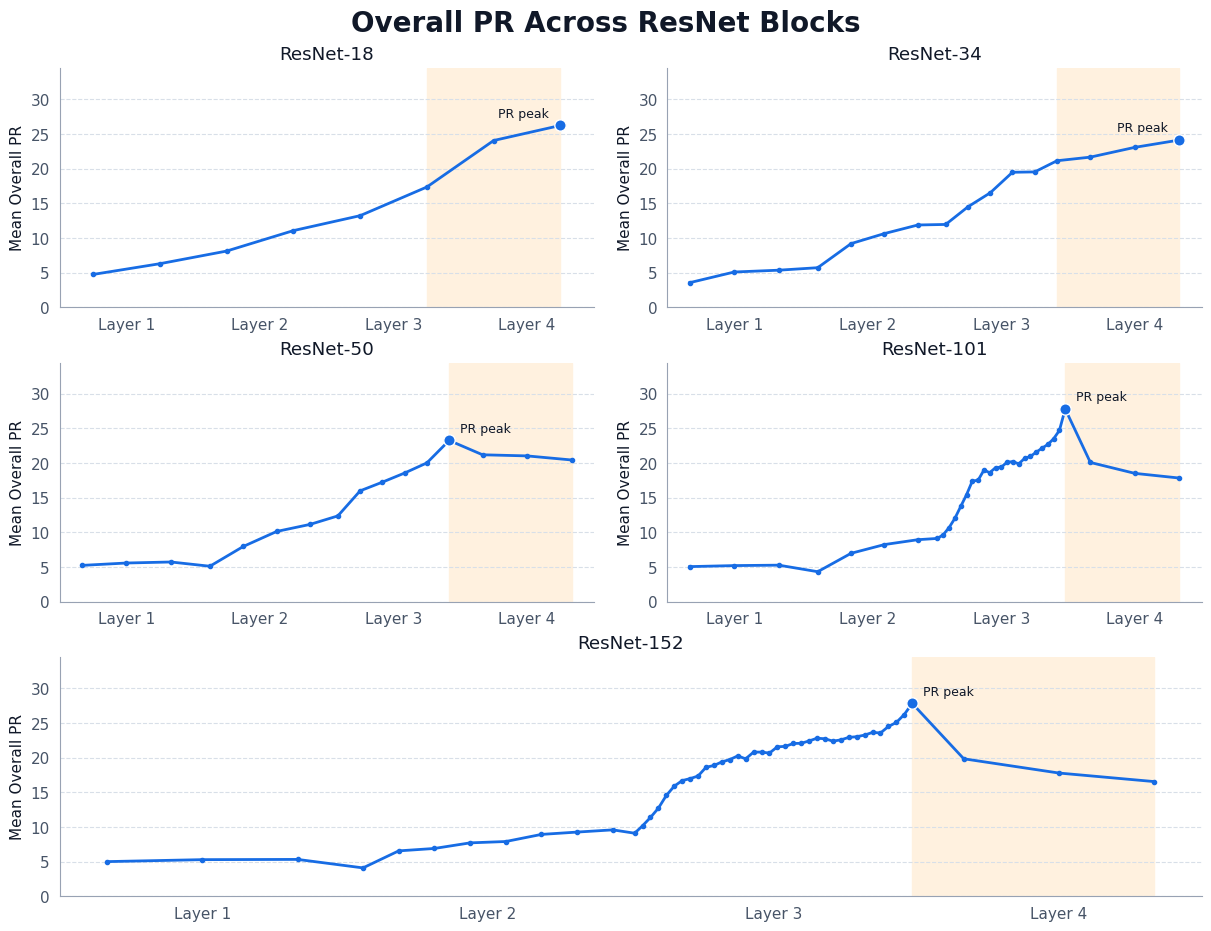

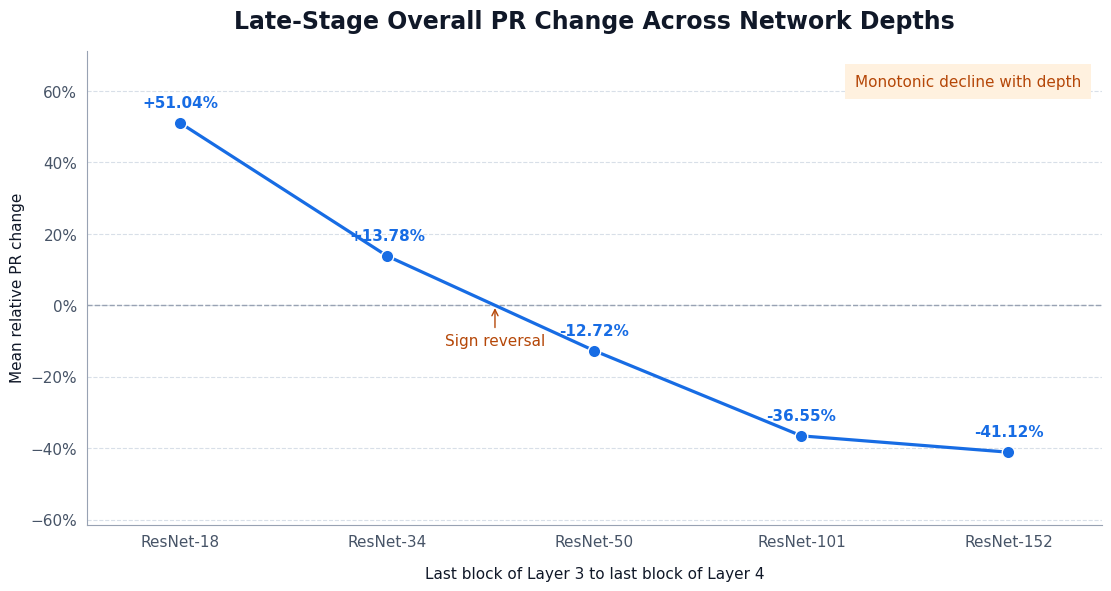

Saved figures and CSVs to /content/drive/MyDrive/ResNet_100_Pairs_Overall_PR_One_Pass/20261127T052016318893Z


In [6]:
# Figure 1: one measured point per block, aligned by stage.
BLUE, INK, MUTED, GRID = "#176ce4", "#101828", "#475467", "#d8dfe8"
ORANGE, SHADE = "#b54708", "#fff1df"
plt.rcParams.update({"font.size": 11, "text.color": INK, "axes.labelcolor": INK})


def style_axis(ax):
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color("#98a2b3")
    ax.tick_params(colors=MUTED, length=0, pad=7)
    ax.grid(axis="y", color=GRID, linestyle="--", linewidth=0.8)
    ax.set_axisbelow(True)


def save_figure(fig, name):
    fig.savefig(RUN_DIR / f"{name}.png", dpi=220, bbox_inches="tight", facecolor="white")
    plt.show()
    plt.close(fig)


fig = plt.figure(figsize=(12, 9.2), layout="constrained")
slots = fig.add_gridspec(3, 2)
axes = [fig.add_subplot(slots[r, c]) for r in range(2) for c in range(2)]
axes.append(fig.add_subplot(slots[2, :]))
fig.suptitle("Overall PR Across ResNet Blocks", fontsize=20, weight="bold")
upper = block_means["mean_pr"].max() * 1.24
for ax, name in zip(axes, MODEL_NAMES, strict=True):
    values = block_means[block_means["model"].eq(name)].sort_values(["stage", "block"])
    widths = values.groupby("stage")["block"].transform("size")
    x = (values["stage"] - 0.5 + (values["block"] - 0.5) / widths).to_numpy()
    y = values["mean_pr"].to_numpy()
    peak = int(y.argmax())
    last_stage3 = x[values["stage"].to_numpy() == 3][-1]
    ax.axvspan(last_stage3, x[-1], color=SHADE, zorder=0)
    ax.plot(x, y, color=BLUE, lw=2, marker="o", ms=3)
    ax.scatter(x[peak], y[peak], color=BLUE, edgecolor="white", s=67, zorder=3)
    peak_dx = -8 if x[peak] >= 4 else 8
    ax.annotate("PR peak", (x[peak], y[peak]), xytext=(peak_dx, 6), textcoords="offset points",
                ha="right" if peak_dx < 0 else "left", fontsize=9)
    ax.set(title=MODEL_LABELS[name], ylabel="Mean Overall PR", xlim=(0.5, 4.5), ylim=(0, upper))
    ax.set_xticks(range(1, 5), [f"Layer {s}" for s in range(1, 5)])
    style_axis(ax)
save_figure(fig, "01_block_mean_overall_pr")

# Figure 2: mean of within-pair percentage changes.
fig, ax = plt.subplots(figsize=(11, 5.8), layout="constrained")
x = np.arange(len(MODEL_NAMES))
y = late_means["mean_change_pct"].to_numpy()
bottom, top = min(0, y.min()), max(0, y.max())
padding = max(5, 0.22 * (top - bottom))
ax.set(xlim=(-0.45, len(x) - 0.55), ylim=(bottom - padding, top + padding),
       ylabel="Mean relative PR change")
ax.set_title("Late-Stage Overall PR Change Across Network Depths", fontsize=17, weight="bold", pad=16)
ax.set_xticks(x, [MODEL_LABELS[name] for name in MODEL_NAMES])
ax.set_xlabel("Last block of Layer 3 to last block of Layer 4", labelpad=12)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
ax.axhline(0, color="#98a2b3", lw=1, linestyle="--")
ax.plot(x, y, marker="o", color=BLUE, lw=2.3, ms=9, markeredgecolor="white")
for xpos, value in zip(x, y, strict=True):
    ax.annotate(f"{value:+.2f}%", (xpos, value), xytext=(0, 9), textcoords="offset points",
                ha="center", va="bottom", color=BLUE, weight="bold")

# Add reference-style callouts only when supported by the measured means.
for i in np.flatnonzero(y[:-1] * y[1:] < 0):
    crossing = x[i] - y[i] / (y[i + 1] - y[i])
    ax.annotate("Sign reversal", (crossing, 0), xytext=(0, -20), textcoords="offset points",
                ha="center", va="top", color=ORANGE,
                arrowprops={"arrowstyle": "->", "color": ORANGE})
if np.all(np.diff(y) < 0):
    ax.text(0.98, 0.95, "Monotonic decline with depth", transform=ax.transAxes, ha="right",
            va="top", color=ORANGE, bbox={"facecolor": SHADE, "edgecolor": "none", "pad": 7})
style_axis(ax)
save_figure(fig, "02_late_stage_relative_pr_change")
print(f"Saved figures and CSVs to {RUN_DIR}")